## EDA with matplotlib

#### Workflow: 
* aggregate or filter in pyspark
    * `agg()`, `where()` `filter()`
* convert with `.toPandas()`
* plot with matplotlib 

### EDA: Superclass Labels

In [3]:
from pyspark.sql import SparkSession
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# ------------- # 
# spark session
spark = SparkSession.builder.getOrCreate()
# ------------- # 
# retrieving preprocessed data
data = spark.read.parquet("/standard/ds7200-apt4c/team2/ptb_superclass_v4")

# using folds 1 - 8 (training folds) for EDA
train = data.filter(F.col("strat_fold") <= 8)

# defining superlabels
suplabs = ["NORM", "MI", "STTC", "CD", "HYP"]

# filtering
counts = train.agg(*[F.sum(c).alias(c) for c in suplabs]).toPandas()

/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

#### superclass counts:

   NORM    MI  STTC    CD   HYP
0  7596  4378  4182  3903  2114
25.6% of ECGs are in Superclass MI


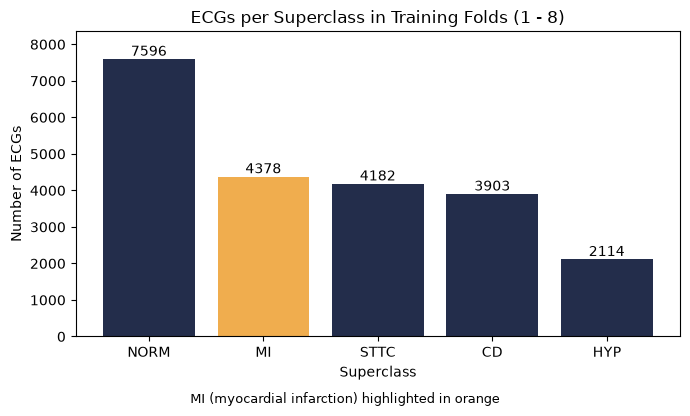

In [29]:
print(counts)

n = train.count()
print(f"{counts['MI'][0]/n:.1%} of ECGs are in Superclass MI")

# plot barchart of superclass counts
fig, ax = plt.subplots(figsize=(7,4))
colorlist = ["#232D4B", "#f0ad4e", "#232D4B", "#232D4B", "#232D4B"]
bars = ax.bar(suplabs, counts.iloc[0], color=colorlist)
ax.bar_label(bars)
ax.set_xlabel("Superclass")
ax.set_ylabel("Number of ECGs")
ax.set_title("ECGs per Superclass in Training Folds (1 - 8)")
fig.text(0.5, -0.02, "MI (myocardial infarction) highlighted in orange", ha="center", fontsize=9)
# keeping margins intact with tight_layout
ax.margins(y=0.1)
plt.tight_layout()
plt.show()

In [18]:
print(f"Total # of ECGs in folds 1 - 8 = {n}")
print(f"Adding up superlabel counts = {(counts['NORM'][0] + counts['MI'][0] + counts["STTC"][0] + counts["CD"][0] + counts["HYP"][0])}")

Total # of ECGs in folds 1 - 8 = 17077
Adding up superlabel counts = 22173


**Note**: There is overlap between the superlabels; some ECGs are labeled more than once

#### superclass co-occurrence

We see that the sum of all the superlabels is greater than the number of labeled ECGs, meaning that some ECGs have more than one cardiac event superlabel.

In [24]:
# counting how many ECGs carry each pair of superlabels

import pandas as pd

super_prs = train.agg(*[F.sum(F.col(a) * F.col(b)).alias(f"{a}_{b}") for a in suplabs for b in suplabs]).toPandas()

# creating a co-occurrence matrix 
coocc = pd.DataFrame(super_prs.iloc[0].values.reshape(5,5), index=suplabs, columns=suplabs)
print(coocc)

/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


      NORM    MI  STTC    CD   HYP
NORM  7596     1    24   332     2
MI       1  4378  1054  1434   649
STTC    24  1054  4182   855  1220
CD     332  1434   855  3903   622
HYP      2   649  1220   622  2114


**Investigating why one ECG has a superlabel of NORM and also MI**.  
* Suspect that the MI is low likelihood.  We changed the likelihood labels to: if there is any likelihood listed, use that label.
* Could also be caused by a conflicting second opinion (with possibly a low likelihood) or
* `initial_autogenerated_report` and `validated_by_human`, which we dropped from dataset `v4`. 

**Using a threshold** was explored but discarded for now for ***simplicity*** and because the ***PTB-XL+ benchmarks*** were processed this way.   

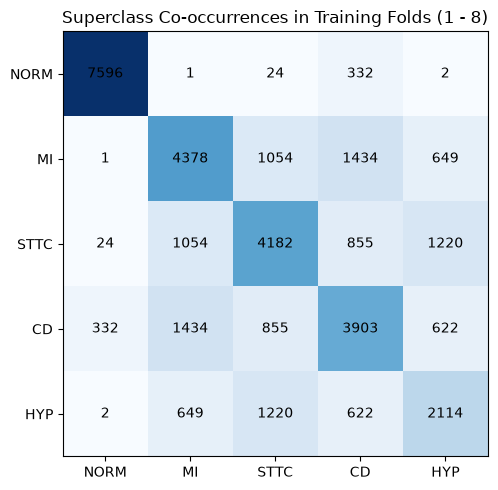

In [28]:
# co-occurrence heatmap

fig, ax = plt.subplots(figsize=(6, 5))
img = ax.imshow(coocc.values, cmap="Blues")

ax.set_xticks(range(5), suplabs)
ax.set_yticks(range(5), suplabs)

for i in range(5): 
    for j in range(5):
        ax.text(j, i, coocc.values[i,j], ha="center", va="center")

ax.set_title("Superclass Co-occurrences in Training Folds (1 - 8)")
plt.tight_layout()
plt.show()

**Discussion**: 
* `MI` occurrs most often in a pair with `CD` (conduction disturbance), then `STTC` (ST segment or T wave changes: cardiac stress)

* `NORM` co-occurs with `CD` far more than with any other superclass cardiac event
    * `CD`
    * https://www.heart.org/en/health-topics/arrhythmia/about-arrhythmia/conduction-disorders